In [1]:
# ==========================================
# CELL 1: SETUP
# ==========================================

import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from matplotlib.animation import FuncAnimation
from pathlib import Path

warnings.filterwarnings("ignore")
plt.style.use("bmh")

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

DATA_PROCESSED = project_root / "data_processed"

print(" Dissertation Dashboard Ready.")

 Dissertation Dashboard Ready.


In [11]:
!pip install nbformat ipykernel notebook

  Using cached jupyter_server-2.17.0-py3-none-any.whl.metadata (8.5 kB)
  Using cached jupyterlab_server-2.28.0-py3-none-any.whl.metadata (5.9 kB)
  Using cached notebook_shim-0.2.4-py3-none-any.whl.metadata (4.0 kB)
  Using cached anyio-4.12.1-py3-none-any.whl.metadata (4.3 kB)
  Using cached argon2_cffi-25.1.0-py3-none-any.whl.metadata (4.1 kB)
  Using cached jupyter_events-0.12.0-py3-none-any.whl.metadata (5.8 kB)
  Using cached overrides-7.7.0-py3-none-any.whl.metadata (5.8 kB)
  Using cached send2trash-2.1.0-py3-none-any.whl.metadata (4.1 kB)
  Using cached terminado-0.18.1-py3-none-any.whl.metadata (5.8 kB)
  Using cached websocket_client-1.9.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached jupyter_lsp-2.3.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached json5-0.13.0-py3-none-any.whl.metad

In [2]:
# ==========================================
# CELL 2: LOAD BACKTESTER
# ==========================================

import importlib
import src.backtester
importlib.reload(src.backtester)

from src.backtester import VectorizedBacktester

In [3]:
champions = {
    ("NIFTY", "LONG"): ("ACE.NS", "ELECON.NS", "nifty500_prices.parquet"),
    ("NIFTY", "BROAD"): ("ACE.NS", "ELECON.NS", "nifty500_2015_prices.parquet"),
    ("SP500", "LONG"): ("A", "PLD", "sp500_prices.parquet"),
    ("SP500", "BROAD"): ("ADI", "DOV", "sp500_2015_prices.parquet"),
}

In [4]:
def compute_equity(market, period, t1, t2, file):

    prices = pd.read_parquet(DATA_PROCESSED / file)
    
    bt = VectorizedBacktester(
        prices,
        market="NIFTY" if market == "NIFTY" else "SPX",
        entry_z=2.0,
        stop_loss=-0.05,
        take_profit=0.15
    )
    
    res = bt.run_pair_backtest(t1, t2)
    
    return res["equity_curve"]

equity_dict = {}

for (market, period), (t1, t2, file) in champions.items():
    equity_dict[(market, period)] = compute_equity(market, period, t1, t2, file)

print("Equity Curves Ready.")

Equity Curves Ready.


In [5]:
# ==========================================
# CELL 5: REGIME TIMELINE CHART
# ==========================================

fig = go.Figure()

for key, equity in equity_dict.items():
    fig.add_trace(go.Scatter(
        x=equity.index,
        y=equity.values,
        mode='lines',
        name=f"{key[0]} {key[1]}"
    ))

# Crisis Shading
fig.add_vrect(x0="2008-01-01", x1="2009-06-01",
              fillcolor="red", opacity=0.2,
              annotation_text="Global Financial Crisis")

fig.add_vrect(x0="2020-02-01", x1="2020-12-01",
              fillcolor="orange", opacity=0.2,
              annotation_text="COVID Crash")

fig.update_layout(
    title="Capital Growth With Crisis Regimes Highlighted",
    yaxis_title="Growth of ₹1",
    xaxis_title="Time",
    template="plotly_white"
)

fig.show()

Animation size has reached 20992494 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


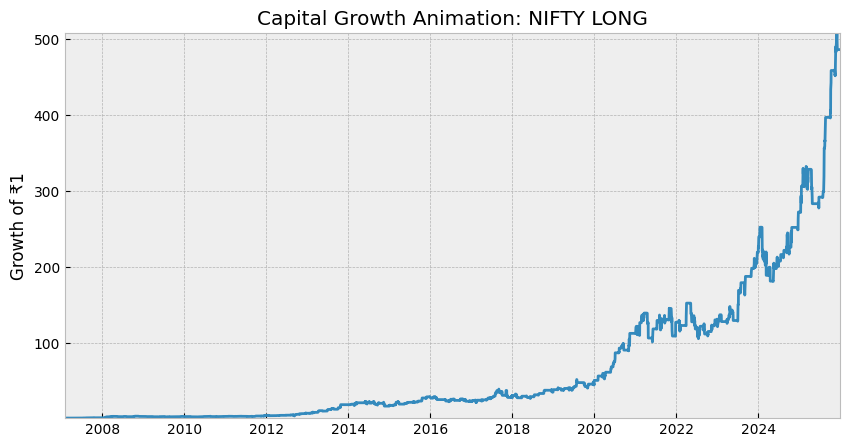

: 

In [ ]:
# ==========================================
# FIXED CAPITAL GROWTH ANIMATION
# ==========================================

from IPython.display import HTML

market, period = ("NIFTY", "LONG")
equity = equity_dict[(market, period)]

fig, ax = plt.subplots(figsize=(10,5))

ax.set_xlim(equity.index.min(), equity.index.max())
ax.set_ylim(equity.min(), equity.max())
ax.set_title(f"Capital Growth Animation: {market} {period}")
ax.set_ylabel("Growth of ₹1")

line, = ax.plot([], [], lw=2)

def init():
    line.set_data([], [])
    return line,

def update(frame):
    x = equity.index[:frame]
    y = equity.values[:frame]
    line.set_data(x, y)
    return line,

ani = FuncAnimation(
    fig,
    update,
    frames=len(equity),
    init_func=init,
    blit=False,
    interval=20
)

HTML(ani.to_jshtml())

In [7]:
# ==========================================
# CELL 7: KPI SUMMARY
# ==========================================

summary = []

for key, equity in equity_dict.items():
    
    total_return = equity.iloc[-1] - 1
    returns = equity.pct_change().dropna()
    sharpe = (returns.mean() / returns.std()) * np.sqrt(252)
    drawdown = ((equity - equity.cummax()) / equity.cummax()).min()
    
    summary.append({
        "Market": key[0],
        "Period": key[1],
        "Total Profit (%)": round(total_return * 100, 2),
        "Sharpe": round(sharpe, 2),
        "Worst Fall (%)": round(drawdown * 100, 2)
    })

df_kpi = pd.DataFrame(summary)
df_kpi

,Market,Period,Total Profit (%),Sharpe,Worst Fall (%)
0,NIFTY,LONG,48534.57,1.12,-31.60
1,NIFTY,BROAD,2641.25,1.08,-31.22
2,SP500,LONG,696.07,0.65,-36.15
3,SP500,BROAD,199.27,0.67,-23.95
